## Ejercicio de Regresión Logística
### Desarrollado por: Angie Alejandra Chipatecua Zárate
**Objetivo:** Bajo este notebook se espera validar y predecir si un cliente tiene la capacidad de pagar o dejará una deuda con el banco, es decir, si entrará en mora. Esto se pretende descubrir a partir de estas 3 variables de entrada (X): Ingresos mensuales, puntaje crediticio y antiguedad laboral. Ahora bien, la variable objetivo (y) será: Crédito aprobado y es la que nos permitirá saber el resultado de la predicción.

### ¿Por qué regresión Logística?
Para empezar, este ejercicio es uno de los más generales y utilizados en banca, los cuales demuestran utilizar este modelo por la clasificación binaria que tiene el problema, es decir, solo tiene dos caminos de salida: Se aprueba o no se aprueba el crédito. Además, este modelo genera probabilidades que permiten ir más allá de una predicción, pues demuestran, por ejemplo el porcentaje exacto de confianza de que se dé un crédito y se apruebe.

### Aplicación del modelo y el ejercicio
A continuación se dará a conocer el paso a paso de cómo se realizará esta predicción usando la regresión logística:


In [1]:
###Importación de librerías requeridas para el ejercicio
import numpy as np #Para cálculos matemáticos
import pandas as pd #Para organizar los datos en tablas
import matplotlib.pyplot as plt #Para realizar gráficos
from sklearn.model_selection import train_test_split #Para entrenar el modelo
from sklearn.linear_model import LogisticRegression #Para usar el método
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report #Para obtener los resultados

In [3]:
### Creación del modelo de datos
#Para este caso se implemente un modelo manual con 16 filas y 4 columnas con las variables mencionadas anteriormente
datos = pd.DataFrame({
    "ingresos_mensuales": [1300000, 1800000, 1900000, 2000000, 2200000, 4000000, 4500000, 5200000, 5800000, 6500000, 7200000, 8000000, 8800000, 9500000, 10500000, 12000000], #Validado en pesos colombianos
    "puntaje_credito":    [450,     480,     510,     530,     560,     600,     620,     650,     670,     700,     710,     740,     760,     780,     800,      820], #Puntaje de 300 a 850
    "antiguedad_laboral": [1,       1,       2,       2,       3,       3,       4,       4,       5,       6,       6,       7,       8,       8,       9,        10], #Medido en años
    "credito_aprobado":   [0,       0,       0,       0,       0,       0,       0,       1,       1,       1,       1,       1,       1,       1,       1,        1] #1=Aprobado, 0= No aprobado
})

datos.head() #Permite ver los datos de los 5 primeros registros

,ingresos_mensuales,puntaje_credito,antiguedad_laboral,credito_aprobado
0,1300000,450,1,0
1,1800000,480,1,0
2,1900000,510,2,0
3,2000000,530,2,0
4,2200000,560,3,0


In [4]:
##Exploración inicial de los datos para saber su tiipo de dato, su análisis general y si son numéricos

print("--- Información general ---")
datos.info() #Muestra un resumen del dataframe creado en el paso 2

print("\n--- Estadísticas descriptivas ---")
print(datos.describe()) #Genera un resumen estadístico de los datos

print("\n--- Distribución de la variable objetivo ---")
print(datos["credito_aprobado"].value_counts()) #Cuenta cuantas veces se repite el valor de aprobación o denegación (variable Y)

--- Información general ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   ingresos_mensuales  16 non-null     int64
 1   puntaje_credito     16 non-null     int64
 2   antiguedad_laboral  16 non-null     int64
 3   credito_aprobado    16 non-null     int64
dtypes: int64(4)
memory usage: 644.0 bytes

--- Estadísticas descriptivas ---
       ingresos_mensuales  puntaje_credito  antiguedad_laboral  \
count        1.600000e+01        16.000000            16.00000   
mean         5.700000e+06       648.750000             4.93750   
std          3.410767e+06       118.145391             2.88603   
min          1.300000e+06       450.000000             1.00000   
25%          2.150000e+06       552.500000             2.75000   
50%          5.500000e+06       660.000000             4.50000   
75%          8.200000e+06       745.000000      

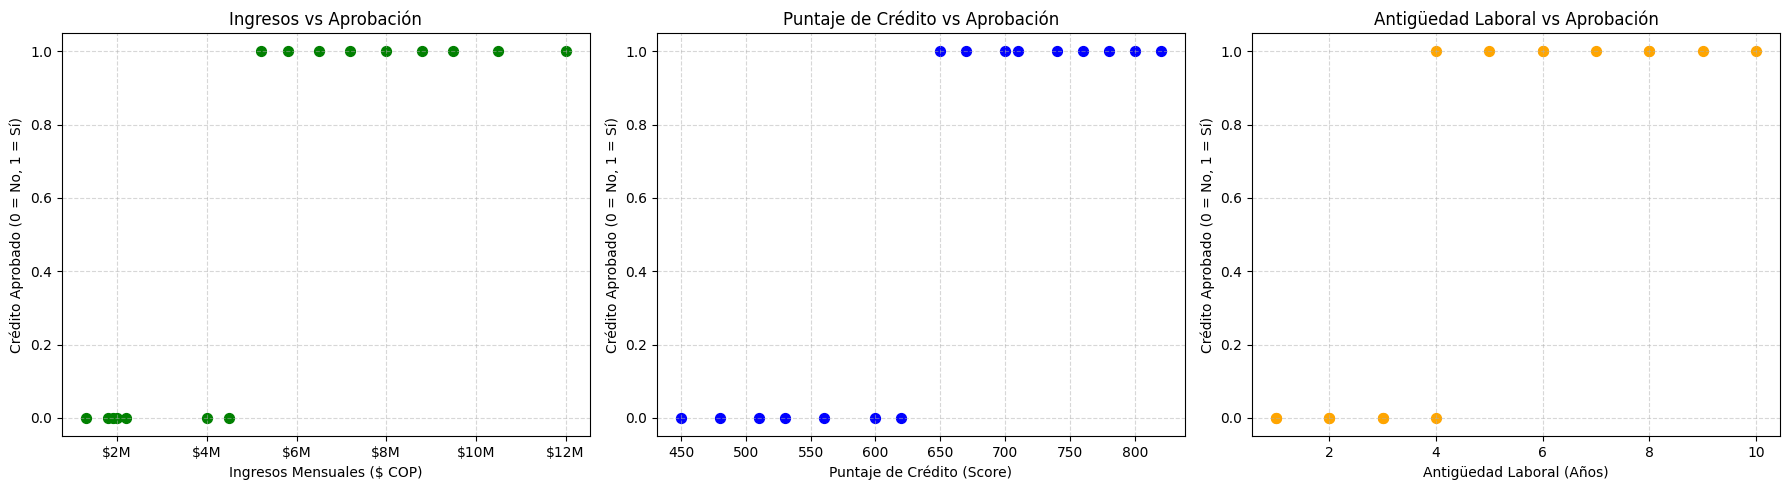

In [7]:
#Visualizar la relación de cada variable con la aprobación del crédito por medio de gráficas
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Crea un lienzo con 3 subgráficas (1 fila x 3 columnas)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Primera gráfica:  Ingresos Mensuales vs Crédito Aprobado
#Axes[0] significa que es la primer gráfica ubicada en el 1x1
axes[0].scatter(datos["ingresos_mensuales"], datos["credito_aprobado"], color='green', s=50) #Se define x como ingresos y y como crédito aprobado
axes[0].set_xlabel("Ingresos Mensuales ($ COP)") #Se agrega un título al eje x
axes[0].set_ylabel("Crédito Aprobado (0 = No, 1 = Sí)") #Se agrega un título al eje y
axes[0].set_title("Ingresos vs Aprobación") #Se agrega un título a la gráfica
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${int(x/1e6)}M")) # Formato en millones (Por ejemplo: $2M)
axes[0].grid(True, linestyle='--', alpha=0.5) #Se agrega una cuadrícula

#Segunda gráfica: Puntaje de Crédito vs Crédito Aprobado
#Axes[1] significa que es la segunda gráfica ubicada en el 1x2
axes[1].scatter(datos["puntaje_credito"], datos["credito_aprobado"], color='blue', s=50) #Se define x como puntaje crédito y y como crédito aprobado
axes[1].set_xlabel("Puntaje de Crédito (Score)") #Se agrega un título al eje x
axes[1].set_ylabel("Crédito Aprobado (0 = No, 1 = Sí)") #Se agrega un título al eje y
axes[1].set_title("Puntaje de Crédito vs Aprobación") # Se agrega un título a la gráfica
axes[1].grid(True, linestyle='--', alpha=0.5) #Se agrega una cuadrícula y transparencia

# Tercera gráfica: Antigüedad Laboral vs Crédito Aprobado
#Axes[2] significa que es la tercera gráfica ubicada en el 1x3
axes[2].scatter(datos["antiguedad_laboral"], datos["credito_aprobado"], color='orange', s=50) #Se define x como antiguedad laboral y y como crédito aprobado
axes[2].set_xlabel("Antigüedad Laboral (Años)") #Se agrega un título al eje x
axes[2].set_ylabel("Crédito Aprobado (0 = No, 1 = Sí)") #Se agrega un título al eje y
axes[2].set_title("Antigüedad Laboral vs Aprobación") #Se agrega un título a la gráfica
axes[2].grid(True, linestyle='--', alpha=0.5) #Se agrega transparencia y una cuadrícula para ver mejor los datos

plt.tight_layout() #Ajusta los elementos para que no se sobrepongan y tengas los espacios y márgenes adecuados
plt.show() #Muestra las gráficas creadas dentro del lienzo

In [8]:
#Definición de x y y
#En este caso se lleva a la aplicación del objetivo, dando a conocer cuales son las variables de entrada y la variable objetivo
X = datos[["ingresos_mensuales", "puntaje_credito", "antiguedad_laboral"]] #Son las variables de entrada (características)
y = datos["credito_aprobado"] #Es la variable objetivo

print("Vista previa de X:")
print(X.head()) #Imprimimos los 5 primeros registros de cada variable x
print("\nVista previa de y:")
print(y.head()) #Se imprimen los 5 primeros registros de la variable objetivo

Vista previa de X:
   ingresos_mensuales  puntaje_credito  antiguedad_laboral
0             1300000              450                   1
1             1800000              480                   1
2             1900000              510                   2
3             2000000              530                   2
4             2200000              560                   3

Vista previa de y:
0    0
1    0
2    0
3    0
4    0
Name: credito_aprobado, dtype: int64


In [9]:
##Dividir datos en entrenamiento y prueba
#Se dividen los datos de entrenamiento y prueba para posteriormente entrenarlos e iniciar con el proceso de predicción
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25, #El 25% de los datos serán destinados a test
    random_state=42, #Asegura que el dataframe se divida exactamente de la misma manera en cada ejecución
    stratify=y #Permite tener balance entre los 2 grupos respecto a los resultados
) #Separa los datos de nuestro dataframe en 2 grupos: Entrenamiento y test. Para este caso se eligen de forma aleatoria.

print(f"Tamaño de X_train: {X_train.shape}")
print(f"Tamaño de X_test: {X_test.shape}")
print("\nDistribución de clases en Entrenamiento:")
print(y_train.value_counts())

Tamaño de X_train: (12, 3)
Tamaño de X_test: (4, 3)

Distribución de clases en Entrenamiento:
credito_aprobado
1    7
0    5
Name: count, dtype: int64


In [10]:
#Creación y entrenamiento del modelo
modelo = LogisticRegression() #Decidimos que modelo aplicar, en este caso será regresión logística dado al argumento encontrado en el informe y en el objetivo de este Notebook
modelo.fit(X_train, y_train) #Se entrena el modelo
print("¡Modelo de Regresión Logística entrenado exitosamente!")

¡Modelo de Regresión Logística entrenado exitosamente!


In [11]:
#Predicción de clases y probabilidades
y_pred = modelo.predict(X_test) #Genera las predicciones con el grupo de prueba
probabilidades = modelo.predict_proba(X_test) #Brinda los porcentajes de participar o no en cada categoría de resultado final

print("Predicciones finales (Clases):", y_pred)
print("\nProbabilidades por clase [P(0), P(1)]:\n", probabilidades)

Predicciones finales (Clases): [0 1 0 1]

Probabilidades por clase [P(0), P(1)]:
 [[1.00000000e+00 2.93768826e-14]
 [0.00000000e+00 1.00000000e+00]
 [7.12823019e-01 2.87176981e-01]
 [0.00000000e+00 1.00000000e+00]]


In [12]:
#Se realiza el cuadro comparativo de los resultados
comparacion = pd.DataFrame({
    "Real": y_test.values,
    "Predicho": y_pred,
    "Probabilidad_Rechazo": probabilidades[:, 0],
    "Probabilidad_Aprobacion": probabilidades[:, 1]
})

comparacion

,Real,Predicho,Probabilidad_Rechazo,Probabilidad_Aprobacion
0,0,0,1.000000,2.937688e-14
1,1,1,0.000000,1.000000e+00
2,0,0,0.712823,2.871770e-01
3,1,1,0.000000,1.000000e+00


In [13]:
#Evaluación del modelo
accuracy = accuracy_score(y_test, y_pred) #Permite calcular el porcentaje total de predicciones correctas sobre el total de la información suministrada
print(f"Accuracy (Exactitud): {accuracy:.2f}\n")

print("Matriz de Confusión:")
print(confusion_matrix(y_test, y_pred)) #Cruza los valores del test cotnra los predichos

print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred)) #Genera un reporte con 3 métricas: Precisión, exhaustividad, F1-Score

Accuracy (Exactitud): 1.00

Matriz de Confusión:
[[2 0]
 [0 2]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [14]:
#Análisis del cambio al umbral de decisión
prob_aprobacion = probabilidades[:, 1] #Se extrae la segunda columna de la matriz de probabilidades, porque contiene la probabilidad de que el crédito se haya aprobado
umbral_estricto = 0.70 #Se va a exigir un 70% o más porcentaje de probabilidad de éxito para la aprobación del crédito

y_pred_estricto = (prob_aprobacion >= umbral_estricto).astype(int) #Realiza la nueva clasificación verificando si se cumple la condición en cada fila (Sí=True, No=False)

comparacion_umbral = pd.DataFrame({ #Se construye una tabla para exponer más fácil los datos y comparar los resultados anteriores vs los del nuevo umbral
    "Real": y_test.values,
    "Prob_Aprobacion": prob_aprobacion,
    "Pred_Umbral_0.50": y_pred,
    "Pred_Umbral_0.70": y_pred_estricto
})

comparacion_umbral

,Real,Prob_Aprobacion,Pred_Umbral_0.50,Pred_Umbral_0.70
0,0,2.937688e-14,0,0
1,1,1.000000e+00,1,1
2,0,2.871770e-01,0,0
3,1,1.000000e+00,1,1


**NOTA:** Todos los resultados y métricas serán explicados a detalle en el informe entregado, el código solo presenta las ejecuciones necesarias para obtener los resultados para poder ser analizados posteriormente.